# Mandatory assignment 3

GitHub repository: https://github.com/villumsimen/TECH2-H26-assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

#### Part 1 - Subpart 1


1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.

In [1]:
import pandas as pd

file = "SCF_10pct.csv"


df = pd.read_csv(file)
df.info(show_counts=True)
df




<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


,id,year,age,educ,stocks,equity
0,0,1989,35,2.0,0.0,0.0
1,1,1989,33,2.0,0.0,0.0
2,2,1989,62,1.0,0.0,0.0
3,3,1989,23,2.0,0.0,0.0
4,4,1989,70,1.0,0.0,0.0
...,...,...,...,...,...,...
5803,5803,2022,21,2.0,0.0,0.0
5804,5804,2022,33,3.0,0.0,0.0
5805,5805,2022,81,2.0,100000.0,100000.0
5806,5806,2022,58,3.0,40000.0,1212000.0


#### Part 1 - Subpart 2


2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.

In [2]:
variables = ["id","year" , "age", "educ", "stocks", "equity"]
#Here we create a copy of the original data frame, which gives us one to work with and one original. 
df_clean=df.copy()

for variable in variables:
    n_before = len(df_clean)
    df_clean = df_clean.dropna(subset=[variable])
    n_after = len(df_clean)
    print(f"{variable}: dropped {n_before - n_after}, remaining : {n_after}")
    
df_clean = df_clean.reset_index(drop=True)



id: dropped 0, remaining : 5808
year: dropped 0, remaining : 5808
age: dropped 0, remaining : 5808
educ: dropped 16, remaining : 5792
stocks: dropped 18, remaining : 5774
equity: dropped 16, remaining : 5758


#### Part 1 - Subpart 3


3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.

In [3]:
n_before = len(df_clean)
df_clean=df_clean.query("age >= 25 & age <= 89")
n_after = len(df_clean) 
dropped = (n_before - n_after)

print(f"We dropped {dropped} observations and {n_after} observations remain") 
df_clean = df_clean.reset_index(drop=True)


We dropped 326 observations and 5432 observations remain


#### Part 1 - Subpart 4


4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [4]:
df_clean["direct"] = (df_clean["stocks"] > 0).astype(int)
df_clean["overall"] = (df_clean["equity"] > 0).astype(int)

df_clean


,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
3,4,1989,70,1.0,0.0,0.0,0,0
4,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5427,5802,2022,77,3.0,0.0,0.0,0,0
5428,5804,2022,33,3.0,0.0,0.0,0,0
5429,5805,2022,81,2.0,100000.0,100000.0,1,1
5430,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

#### Part 2 - Subpart 1

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).

In [5]:
def participation_rate(indicator):
    """Return the share of ones in a nonempty sequence of 0/1 values, in percent."""
    n0=0
    n1=0

    for value in indicator:
        if value == 1:
            n1= n1 + 1
        elif value == 0:
            n0= n0 + 1
    rate = n1/(len(indicator)) * 100
    return rate
 







#### Part 2 - Subpart 2

2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.

In [6]:
direct_rate = participation_rate(df_clean["direct"])
overall_rate = participation_rate(df_clean["overall"])

print(f"{direct_rate:.2f}% of all households participate directly and "
f"{overall_rate:.2f}% participate overall")







16.96% of all households participate directly and 49.41% participate overall


#### Part 2 - Subpart 3

3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [7]:
direct_rate_pd=(df_clean["direct"].mean().round(4)* 100)
overall_rate_pd =(df_clean["overall"].mean().round(4) * 100)

print(f"{direct_rate_pd}% of households participate directly in the stockmarket")
print(f"{overall_rate_pd}% of households participate in the overall stockmarket.")





16.96% of households participate directly in the stockmarket
49.41% of households participate in the overall stockmarket.


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

#### Part 3 - Subpart 1

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).

In [8]:
educ_levels = [1,2,3,4]


direct_rates = []
overall_rates = [] 

for level in educ_levels:
    subset = df_clean[df_clean["educ"] == level]
    direct_rates.append(participation_rate(subset["direct"]))
    overall_rates.append(participation_rate(subset["overall"]))





#### Part 3 - Subpart 2 

2. Display the results, rounding rates to one decimal place.

In [9]:
for i in range (len(educ_levels)):
    print(f"Education level {educ_levels[i]}:"
    f"{direct_rates[i]:.1f}% directly invested, "
    f"{overall_rates[i]:.1f}% overall")


Education level 1:4.4% directly invested, 17.3% overall
Education level 2:11.4% directly invested, 39.9% overall
Education level 3:13.5% directly invested, 48.3% overall
Education level 4:30.5% directly invested, 73.5% overall


#### Part 3 - Subpart 3

3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.

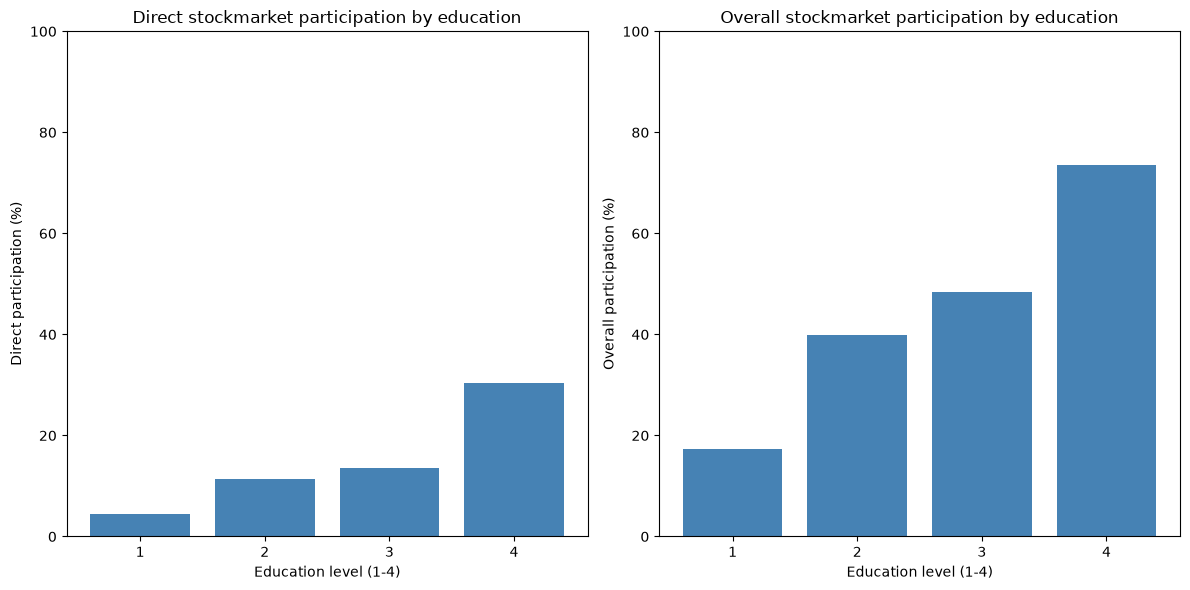

In [10]:
import matplotlib.pyplot as plt


fig, (ax1,ax2) = plt.subplots(1,2, figsize = (12,6))

ax1.bar(educ_levels,direct_rates,color = "steelblue")
ax1.set_title("Direct stockmarket participation by education")
ax1.set_xlabel("Education level (1-4)")
ax1.set_ylabel("Direct participation (%)")
ax1.set_ylim(0,100)
ax1.set_xticks(educ_levels)


ax2.bar(educ_levels,overall_rates,color = "steelblue")
ax2.set_title("Overall stockmarket participation by education")
ax2.set_xlabel("Education level (1-4)")
ax2.set_ylabel("Overall participation (%)")
ax2.set_ylim(0,100)
ax2.set_xticks(educ_levels)

plt.tight_layout()
plt.show()






#### Part 3 - Subpart 4

4. In two or three sentences, describe the education pattern.

Both direct and overall participation rise with education.Direct participation goes from 4.4% for households without high school to 30.5% for those with a bachelor's degree or more, and overall participation goes from 17.3% to 73.5%. The gap between education groups is larger for overall than for direct participation, and even among the most educated, direct stock ownership is much less common than holding equity in some form. 

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

#### Part 4 - Subpart 1


1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.

In [11]:
years = df_clean["year"].unique()

direct_rates_yearly = []
overall_rates_yearly = [] 

for year in years: 
    subset = df_clean[df_clean["year"] == year]
    direct_rates_yearly.append(participation_rate(subset["direct"]))
    overall_rates_yearly.append(participation_rate(subset["overall"]))



    

#### Part 4 - Subpart 2

2. Create a line plot showing both participation rates over time in a single figure.

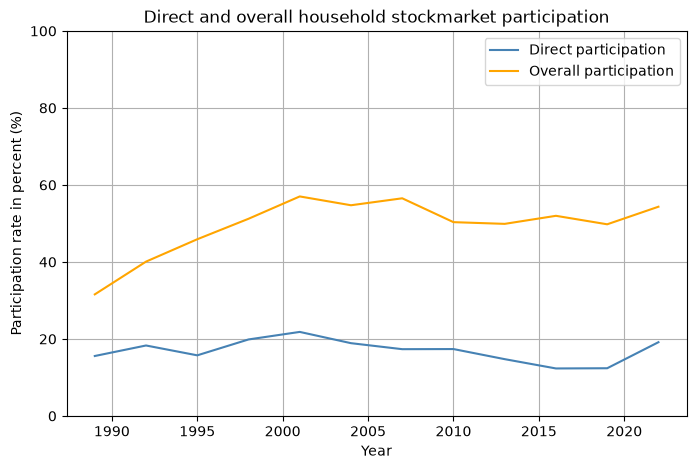

In [12]:

fig, ax = plt.subplots(figsize = (8,5))

ax.plot(years,direct_rates_yearly,color="steelblue",label= "Direct participation")
ax.plot(years,overall_rates_yearly,color="orange",label = "Overall participation")
ax.set_title("Direct and overall household stockmarket participation")
ax.set_ylim(0,100)
ax.set_ylabel("Participation rate in percent (%)")
ax.set_xlabel("Year")
ax.grid()
ax.legend()



#### Part 4 - Subpart 3

3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.

In [ ]:
direct_change = direct_rates_yearly[-1] - direct_rates_yearly[0]
overall_change = overall_rates_yearly[-1] - overall_rates_yearly[0]
print(f"The change in direct stockmarket participation from 1989 to 2022 is {direct_change:.2f} percentage points.")
print(f"The change in overall stockmarket participation from 1989 to 2022 is {overall_change:.2f} percentage points.")




The change in direct stockmarket participation from 1989 to 2022 is 3.58 percentage points.
The change in overall stockmarket participation from 1989 to 2022 is 22.76 percentage points.


#### Part 4 - Subpart 4

4. Describe the main time patterns in two or three sentences.

Between 1989 and 2022, direct participation rose by only 3.58 percentage points, while overall participation rose by 22.76 percentage points.The line plot shows that direct participation moved up and down along the way, so the small net change hides swings between the survey years. Overall participation rose mainly in the earlier part of the period and then stayed at a similar level.

***
## AI-use statement


I used Claude Code through its VS Code integration as a tutor and reviewer while working on this assignment. I used it to:

- get feedback on my code comments (clarity, typos, accuracy);
- understand error messages and debug my code;
- get explanations of concepts used in the assignment;
- get suggestions for how to structure the loops in Parts 3 and 4, and for improving plot layout;
- check my reported numbers against an independent calculation.

I wrote all the code in the notebook myself by typing it in. Some of it follows or adapts code suggested by AI, and I reviewed and ran all of it. The written descriptions of the education and time patterns are my own interpretation of my results, although the AI gave feedback on a draft.
